In [2]:
import pandas as pd
import geopandas as gpd
import os

In [3]:
BASE_DIR = os.getcwd()

shp_path = os.path.join(
    BASE_DIR, "data", "ken_admin_boundaries", "ken_admin1.shp"
)

pop_path = os.path.join(
    BASE_DIR, "data", "2019-population_census-report-per-county.csv"
)

# Read the population data and administrative boundaries
df = pd.read_csv(pop_path)
gdf = gpd.read_file(shp_path)

In [4]:
print(df.columns)
print(df.dtypes)
df.head()

Index(['County', 'Total_Population19', 'Male populatio 2019',
       'Female population 2019', 'Households', 'Av_HH_Size', 'LandArea',
       'Population Density', 'Population in 2009', 'Pop_change',
       'Intersex population 2019'],
      dtype='str')
County                        str
Total_Population19            str
Male populatio 2019           str
Female population 2019        str
Households                    str
Av_HH_Size                  int64
LandArea                      str
Population Density            str
Population in 2009            str
Pop_change                    str
Intersex population 2019    int64
dtype: object


,County,Total_Population19,Male populatio 2019,Female population 2019,Households,Av_HH_Size,LandArea,Population Density,Population in 2009,Pop_change,Intersex population 2019
0,Baringo,"666,763","336,322","330,428","142,518",5,"10,976",61,"555,561","111,202",13
1,Bomet,"875,689","434,287","441,379","187,641",5,"2,531",346,"724,186","151,503",23
2,Bungoma,"1,670,570","812,146","858,389","358,796",5,"3,024",552,"1,630,934","39,636",35
3,Busia,"893,681","426,252","467,401","198,152",5,"1,696",527,"488,075","405,606",28
4,Elgeyo-Marakwet,"454,480","227,317","227,151","99,861",5,"3,032",150,"369,998","84,482",12


In [5]:
#Rename columns for consistency
df.rename(columns={
    "County": "county",
    "Total_Population19": "population 2019",
    "Male populatio 2019": "male_pop 2019",
    "Female population 2019": "female_pop 2019",
    "Population in 2009": "population 2009",
    "Intersex population 2019": "intersex_pop 2019"   
}, inplace=True)


In [6]:
#Drop unnecessary columns and sort by county
pop_county = df[["county", "population 2019", "male_pop 2019", "female_pop 2019", "intersex_pop 2019", "population 2009"]].sort_values(by="county").reset_index(drop=True)

pop_county = pop_county[["county", "population 2019", "male_pop 2019", "female_pop 2019", "intersex_pop 2019", "population 2009"]]
pop_county.head()

,county,population 2019,male_pop 2019,female_pop 2019,intersex_pop 2019,population 2009
0,Baringo,"666,763","336,322","330,428",13,"555,561"
1,Bomet,"875,689","434,287","441,379",23,"724,186"
2,Bungoma,"1,670,570","812,146","858,389",35,"1,630,934"
3,Busia,"893,681","426,252","467,401",28,"488,075"
4,Elgeyo-Marakwet,"454,480","227,317","227,151",12,"369,998"


In [7]:
#Change data type from string to int
cols = ["population 2019", "male_pop 2019", "female_pop 2019", "population 2009"]

for col in cols:
    pop_county[col] = pop_county[col].str.replace(',', '').astype(int)

pop_county.dtypes

county                 str
population 2019      int64
male_pop 2019        int64
female_pop 2019      int64
intersex_pop 2019    int64
population 2009      int64
dtype: object

In [8]:
#Add column for difference between population 2019 and 2009
pop_county["pop_difference"] = pop_county["population 2019"] - pop_county["population 2009"]
pop_county.head()

,county,population 2019,male_pop 2019,female_pop 2019,intersex_pop 2019,population 2009,pop_difference
0,Baringo,666763,336322,330428,13,555561,111202
1,Bomet,875689,434287,441379,23,724186,151503
2,Bungoma,1670570,812146,858389,35,1630934,39636
3,Busia,893681,426252,467401,28,488075,405606
4,Elgeyo-Marakwet,454480,227317,227151,12,369998,84482


In [9]:
print(gdf.columns)
print(gdf.dtypes)
gdf.head()

Index(['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode',
       'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode',
       'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1',
       'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry'],
      dtype='str')
adm1_name                str
adm1_name1            object
adm1_name2            object
adm1_name3            object
adm1_pcode               str
adm0_name                str
adm0_name1            object
adm0_name2            object
adm0_name3            object
adm0_pcode               str
valid_on      datetime64[ms]
valid_to      datetime64[ms]
area_sqkm            float64
version                  str
lang                     str
lang1                 object
lang2                 object
lang3                 object
adm1_ref_n               str
center_lat           float64
center_lon           float64
geometry            geometry
dtype: object


,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,adm0_name,adm0_name1,adm0_name2,adm0_name3,adm0_pcode,...,area_sqkm,version,lang,lang1,lang2,lang3,adm1_ref_n,center_lat,center_lon,geometry
0,Baringo,None,None,None,KE030,Kenya,None,None,None,KE,...,10889.239313,v01,en,None,None,None,Baringo,0.726352,36.018591,"POLYGON ((35.7839 1.65557, 35.78496 1.65554, 3..."
1,Bomet,None,None,None,KE036,Kenya,None,None,None,KE,...,2438.219727,v01,en,None,None,None,Bomet,-0.716095,35.238459,"POLYGON ((35.4736 -0.3992, 35.47845 -0.40663, ..."
2,Bungoma,None,None,None,KE039,Kenya,None,None,None,KE,...,3016.174229,v01,en,None,None,None,Bungoma,0.785694,34.718757,"POLYGON ((34.62017 1.10228, 34.62133 1.1016, 3..."
3,Busia,None,None,None,KE040,Kenya,None,None,None,KE,...,1811.571693,v01,en,None,None,None,Busia,0.375707,34.265111,"POLYGON ((34.36097 0.7773, 34.36172 0.77696, 3..."
4,Elgeyo-Marakwet,None,None,None,KE028,Kenya,None,None,None,KE,...,3008.391184,v01,en,None,None,None,Elgeyo-Marakwet,0.745102,35.560856,"POLYGON ((35.69818 1.28225, 35.69788 1.27905, ..."


In [10]:
#Drop unnecessary columns and sort by adm1_name
county_gdf = gdf[["adm1_name", "adm1_pcode", "adm0_name", "adm0_pcode", "geometry"]].sort_values(by="adm1_name").reset_index(drop=True)

print(county_gdf.dtypes)
county_gdf.head()

adm1_name          str
adm1_pcode         str
adm0_name          str
adm0_pcode         str
geometry      geometry
dtype: object


,adm1_name,adm1_pcode,adm0_name,adm0_pcode,geometry
0,Baringo,KE030,Kenya,KE,"POLYGON ((35.7839 1.65557, 35.78496 1.65554, 3..."
1,Bomet,KE036,Kenya,KE,"POLYGON ((35.4736 -0.3992, 35.47845 -0.40663, ..."
2,Bungoma,KE039,Kenya,KE,"POLYGON ((34.62017 1.10228, 34.62133 1.1016, 3..."
3,Busia,KE040,Kenya,KE,"POLYGON ((34.36097 0.7773, 34.36172 0.77696, 3..."
4,Elgeyo-Marakwet,KE028,Kenya,KE,"POLYGON ((35.69818 1.28225, 35.69788 1.27905, ..."


In [11]:
#Check county names are similar in both datasets
df_names = [df["county"].astype(str).str.strip().reset_index(drop=True)]
gdf_names = [county_gdf["adm1_name"].astype(str).str.strip().reset_index(drop=True)]

if df_names[0].sort_values().equals(
    gdf_names[0].sort_values().reset_index(drop=True)):
    print("The columns match.")
else:
    print("The columns do not match")

The columns match.


In [12]:
pop_county.head()

,county,population 2019,male_pop 2019,female_pop 2019,intersex_pop 2019,population 2009,pop_difference
0,Baringo,666763,336322,330428,13,555561,111202
1,Bomet,875689,434287,441379,23,724186,151503
2,Bungoma,1670570,812146,858389,35,1630934,39636
3,Busia,893681,426252,467401,28,488075,405606
4,Elgeyo-Marakwet,454480,227317,227151,12,369998,84482


In [13]:
data = county_gdf.merge(
    pop_county,
    left_on="adm1_name",
    right_on="county",
    how="left"
)

data.head()

,adm1_name,adm1_pcode,adm0_name,adm0_pcode,geometry,county,population 2019,male_pop 2019,female_pop 2019,intersex_pop 2019,population 2009,pop_difference
0,Baringo,KE030,Kenya,KE,"POLYGON ((35.7839 1.65557, 35.78496 1.65554, 3...",Baringo,666763,336322,330428,13,555561,111202
1,Bomet,KE036,Kenya,KE,"POLYGON ((35.4736 -0.3992, 35.47845 -0.40663, ...",Bomet,875689,434287,441379,23,724186,151503
2,Bungoma,KE039,Kenya,KE,"POLYGON ((34.62017 1.10228, 34.62133 1.1016, 3...",Bungoma,1670570,812146,858389,35,1630934,39636
3,Busia,KE040,Kenya,KE,"POLYGON ((34.36097 0.7773, 34.36172 0.77696, 3...",Busia,893681,426252,467401,28,488075,405606
4,Elgeyo-Marakwet,KE028,Kenya,KE,"POLYGON ((35.69818 1.28225, 35.69788 1.27905, ...",Elgeyo-Marakwet,454480,227317,227151,12,369998,84482


In [14]:
#Remove duplicate county column
data = data.drop(columns=["county"])

#Normalize column names
data.columns = [
    col.strip().lower().replace(" ", "_")
    for col in data.columns
]

#Calculate growth percentage
data["growth_percent"] = data["pop_difference"] / data["population_2009"] *100

#Calculate male percentage
data["male_percent"] = data["male_pop_2019"] / data["population_2019"] *100

#Calculate female percentage
data["female_percent"] = data["female_pop_2019"] / data["population_2019"] *100

#Calculating population density (pop/area). Area should be in km2
#Project data to Equal Area
projected = data.to_crs(epsg=6933)
data["area_km2"] = projected.geometry.area / 1000000

data["population_density"] = data["population_2019"] / data["area_km2"]

data.head()


,adm1_name,adm1_pcode,adm0_name,adm0_pcode,geometry,population_2019,male_pop_2019,female_pop_2019,intersex_pop_2019,population_2009,pop_difference,growth_percent,male_percent,female_percent,area_km2,population_density
0,Baringo,KE030,Kenya,KE,"POLYGON ((35.7839 1.65557, 35.78496 1.65554, 3...",666763,336322,330428,13,555561,111202,20.016164,50.441011,49.557039,10889.239313,61.231366
1,Bomet,KE036,Kenya,KE,"POLYGON ((35.4736 -0.3992, 35.47845 -0.40663, ...",875689,434287,441379,23,724186,151503,20.920454,49.593748,50.403625,2438.219727,359.150978
2,Bungoma,KE039,Kenya,KE,"POLYGON ((34.62017 1.10228, 34.62133 1.1016, 3...",1670570,812146,858389,35,1630934,39636,2.430264,48.614904,51.383001,3016.174229,553.870524
3,Busia,KE040,Kenya,KE,"POLYGON ((34.36097 0.7773, 34.36172 0.77696, 3...",893681,426252,467401,28,488075,405606,83.103212,47.696214,52.300653,1811.571693,493.318042
4,Elgeyo-Marakwet,KE028,Kenya,KE,"POLYGON ((35.69818 1.28225, 35.69788 1.27905, ...",454480,227317,227151,12,369998,84482,22.833096,50.016942,49.980417,3008.391184,151.070779


In [15]:
#New list of columns with geometry added at the end
new_column_order = [col for col in data.columns if col != "geometry"] + ["geometry"]

#Re-order DataFrame with new column list
data = data[new_column_order]

print(data.columns.tolist())
print(data.crs)

['adm1_name', 'adm1_pcode', 'adm0_name', 'adm0_pcode', 'population_2019', 'male_pop_2019', 'female_pop_2019', 'intersex_pop_2019', 'population_2009', 'pop_difference', 'growth_percent', 'male_percent', 'female_percent', 'area_km2', 'population_density', 'geometry']
EPSG:4326


In [16]:
import matplotlib.pyplot as plt


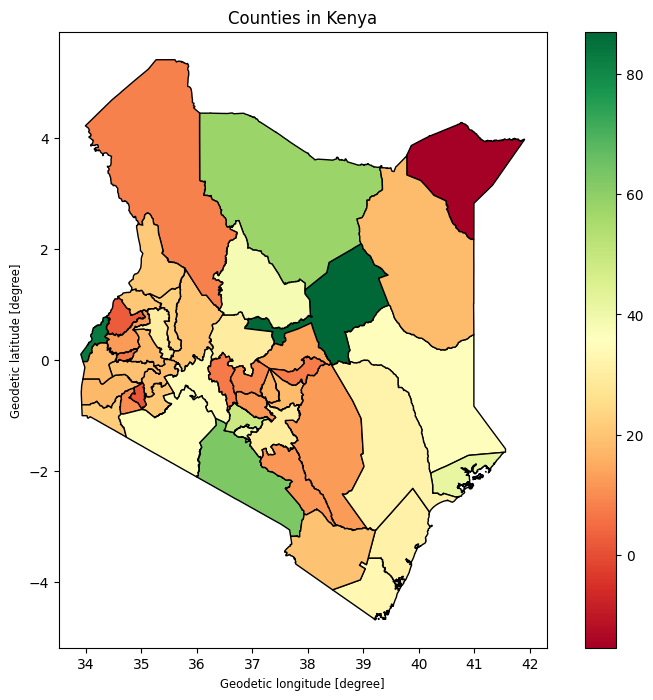

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
data.plot(
    ax=ax,
    column="growth_percent",
    cmap="RdYlGn",
    edgecolor="black",
    legend=True
)
ax.set_title("Population Percentage Growth in Kenya")
plt.show()

In [210]:
# Export data
data.to_crs("EPSG:4326").to_file(
    "../Input/kenya_counties.geojson",
    driver="GeoJSON"
)